In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr

def create_distance_matrix(shape):
    M, N = shape
    u = np.arange(M)
    v = np.arange(N)
    U, V = np.meshgrid(v, u)
    return np.sqrt((U - N//2)**2 + (V - M//2)**2)

def ideal_lpf(shape, D0):
    D = create_distance_matrix(shape)
    H = np.zeros_like(D)
    H[D <= D0] = 1
    return H

def butterworth_lpf(shape, D0, n):
    D = create_distance_matrix(shape)
    return 1 / (1 + (D / D0)**(2 * n))

def gaussian_lpf(shape, D0):
    D = create_distance_matrix(shape)
    return np.exp(-(D**2) / (2 * (D0**2)))

def apply_filter(img, H):
    F = np.fft.fft2(img)
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * H
    G = np.fft.ifftshift(G_shift)
    img_back = np.abs(np.fft.ifft2(G))
    return np.clip(img_back, 0, 255).astype(np.uint8)

img = cv2.imread('img.png', cv2.IMREAD_GRAYSCALE)

D0 = 30 | PSNR ILPF: 18.39 dB | PSNR BLPF (n=2): 18.71 dB


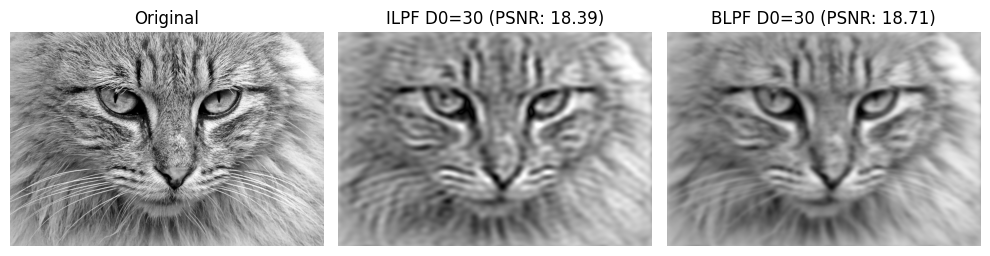

D0 = 100 | PSNR ILPF: 20.51 dB | PSNR BLPF (n=2): 21.32 dB


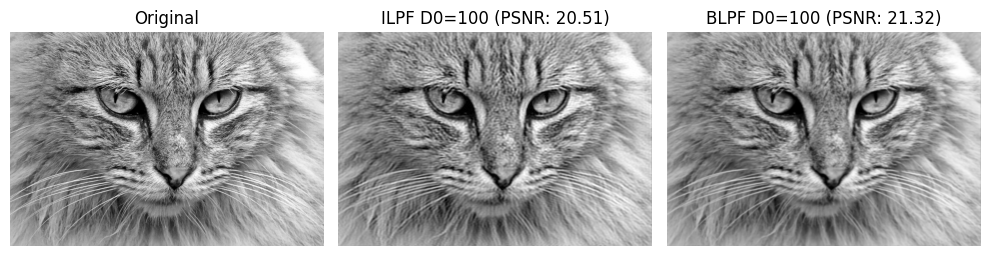

In [5]:
for D0 in [30, 100]:
    H_ilpf = ideal_lpf(img.shape, D0)
    img_ilpf = apply_filter(img, H_ilpf)
    psnr_ilpf = psnr(img, img_ilpf)

    H_blpf = butterworth_lpf(img.shape, D0, n=2)
    img_blpf = apply_filter(img, H_blpf)
    psnr_blpf = psnr(img, img_blpf)

    print(f"D0 = {D0} | PSNR ILPF: {psnr_ilpf:.2f} dB | PSNR BLPF (n=2): {psnr_blpf:.2f} dB")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(img_ilpf, cmap='gray')
    plt.title(f'ILPF D0={D0} (PSNR: {psnr_ilpf:.2f})')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(img_blpf, cmap='gray')
    plt.title(f'BLPF D0={D0} (PSNR: {psnr_blpf:.2f})')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

Orde n = 1 | PSNR ILPF: 18.39 dB | PSNR BLPF: 19.08 dB
Orde n = 2 | PSNR ILPF: 18.39 dB | PSNR BLPF: 18.71 dB
Orde n = 3 | PSNR ILPF: 18.39 dB | PSNR BLPF: 18.60 dB
Orde n = 4 | PSNR ILPF: 18.39 dB | PSNR BLPF: 18.55 dB


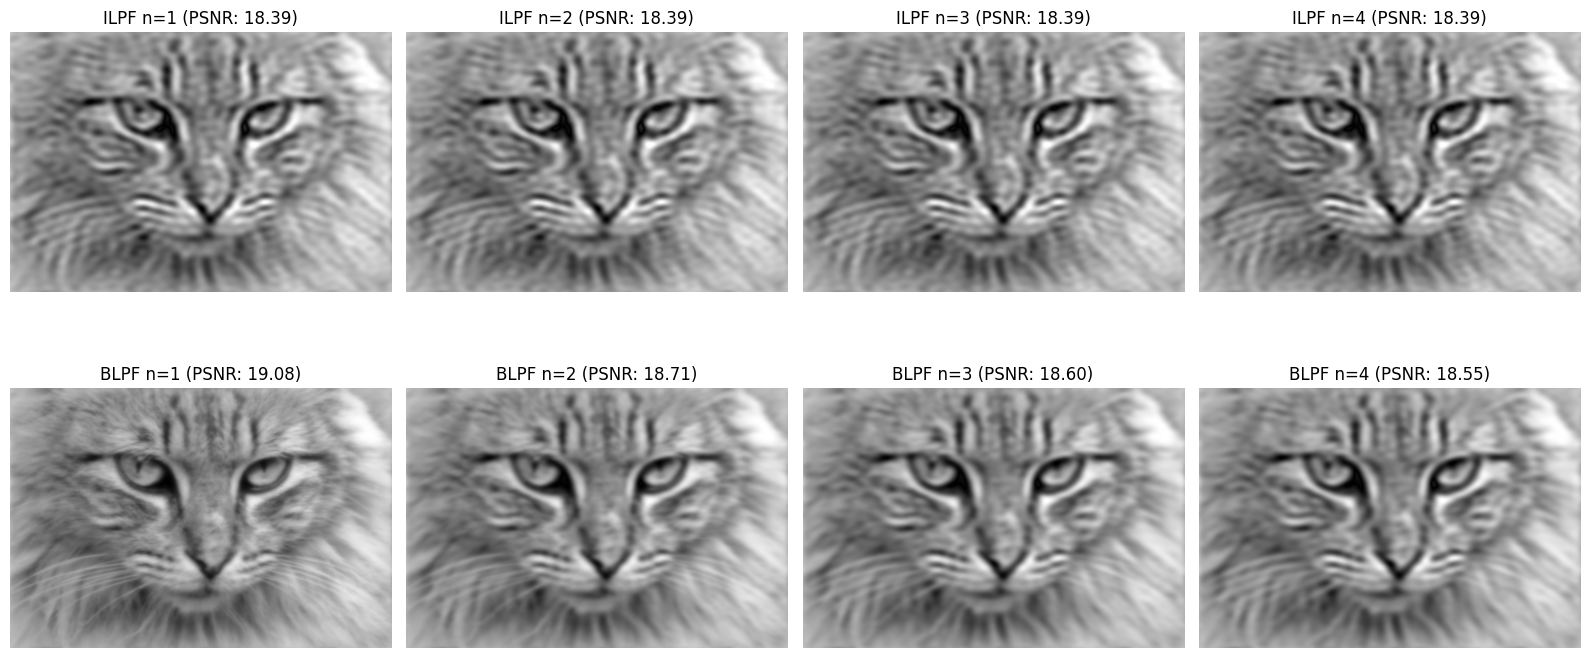

In [6]:
D0_test = 30
H_ilpf_30 = ideal_lpf(img.shape, D0_test)
img_ilpf_30 = apply_filter(img, H_ilpf_30)
psnr_ilpf_fixed = psnr(img, img_ilpf_30)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, n in enumerate([1, 2, 3, 4]):
    H_blpf_n = butterworth_lpf(img.shape, D0_test, n)
    img_blpf_n = apply_filter(img, H_blpf_n)
    psnr_blpf_n = psnr(img, img_blpf_n)

    print(f"Orde n = {n} | PSNR ILPF: {psnr_ilpf_fixed:.2f} dB | PSNR BLPF: {psnr_blpf_n:.2f} dB")

    axes[0, idx].imshow(img_ilpf_30, cmap='gray')
    axes[0, idx].set_title(f'ILPF n={n} (PSNR: {psnr_ilpf_fixed:.2f})')
    axes[0, idx].axis('off')

    axes[1, idx].imshow(img_blpf_n, cmap='gray')
    axes[1, idx].set_title(f'BLPF n={n} (PSNR: {psnr_blpf_n:.2f})')
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()

PSNR ILPF      : 19.13 dB
PSNR BLPF (n=2): 19.59 dB
PSNR GLPF      : 19.89 dB


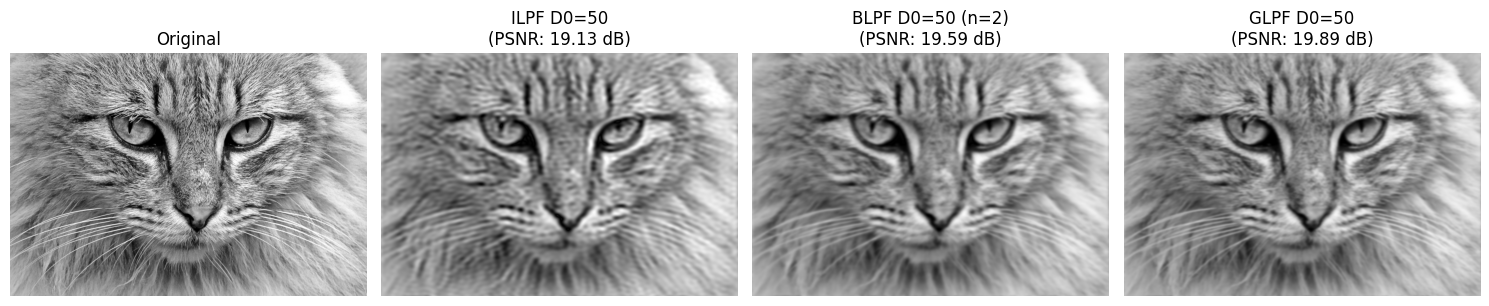

In [7]:
D0_comp = 50
H_i = ideal_lpf(img.shape, D0_comp)
H_b = butterworth_lpf(img.shape, D0_comp, n=2)
H_g = gaussian_lpf(img.shape, D0_comp)

img_i = apply_filter(img, H_i)
img_b = apply_filter(img, H_b)
img_g = apply_filter(img, H_g)

psnr_i = psnr(img, img_i)
psnr_b = psnr(img, img_b)
psnr_g = psnr(img, img_g)

print(f"PSNR ILPF      : {psnr_i:.2f} dB")
print(f"PSNR BLPF (n=2): {psnr_b:.2f} dB")
print(f"PSNR GLPF      : {psnr_g:.2f} dB")

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_i, cmap='gray')
plt.title(f'ILPF D0=50\n(PSNR: {psnr_i:.2f} dB)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_b, cmap='gray')
plt.title(f'BLPF D0=50 (n=2)\n(PSNR: {psnr_b:.2f} dB)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(img_g, cmap='gray')
plt.title(f'GLPF D0=50\n(PSNR: {psnr_g:.2f} dB)')
plt.axis('off')

plt.tight_layout()
plt.show()